In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, adjusted_rand_score, rand_score
from sklearn.feature_extraction import text
from sklearn.decomposition import PCA
import nltk
nltk.download('wordnet')
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from collections import Counter

[nltk_data] Downloading package wordnet to /home/jack/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/jack/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [2]:
def plot_clustering_error_and_silhouette(clustering_data,silhouetteScores):
    fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

    axs[0].plot(
        [k for k in stopWordNumber], 
        [result.inertia_ for result in clustering_data]
    )
    axs[0].set_xlabel("Number of stopWordNumbers removed")
    axs[0].set_ylabel("Clustering error")
    axs[0].grid()
    
    axs[1].plot(
        [k for k in stopWordNumber], 
        [s for s in silhouetteScores]
    )
    axs[1].set_xlabel("Number of stopWordNumbers removed")
    axs[1].set_ylabel("Silhouette")#Compute the mean Silhouette Coefficient of all samples.
    axs[1].grid()

    plt.tight_layout()
    plt.show()

Trying to see how the choiche of how many stopwords to remove impacts the clustering. We considered the most frequent words as stopwords.

Silhouette score for 7 clusters: -0.0004970979509904739
Silhouette score for 7 clusters: 0.00198026124489779
Silhouette score for 7 clusters: 0.00198026124489779
Silhouette score for 7 clusters: 0.002103206533038257
Silhouette score for 7 clusters: 0.002103206533038257
Silhouette score for 7 clusters: 0.0028253205659645305
Silhouette score for 7 clusters: 0.0028253205659645305
Silhouette score for 7 clusters: 0.00284366376478529
Silhouette score for 7 clusters: 0.00284366376478529
Silhouette score for 7 clusters: 0.001855405260157973
Silhouette score for 7 clusters: 0.001855405260157973
Silhouette score for 7 clusters: 0.0019332385756675818
Silhouette score for 7 clusters: 0.0019332385756675818
Silhouette score for 7 clusters: 0.0012794939483593585
Silhouette score for 7 clusters: 0.0012794939483593585
Silhouette score for 7 clusters: 0.002191071098017108
Silhouette score for 7 clusters: 0.002191071098017108
Silhouette score for 7 clusters: 0.0009792858306302739
Silhouette score for 7 

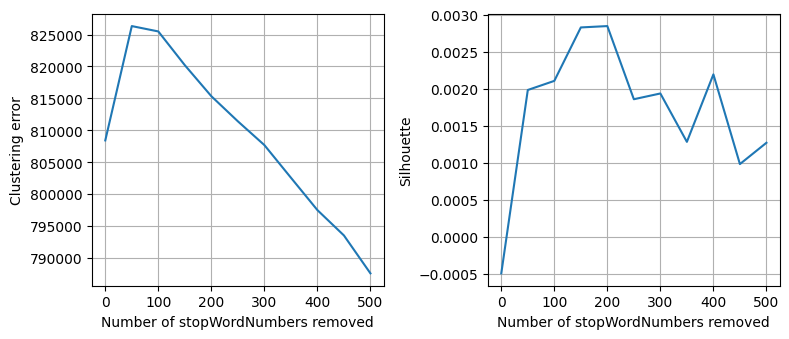

In [ ]:
stopWordNumber = range(0, 550, 50)

def remove_selected_words(text):
    return ' '.join([word for word in text.split() if word not in remove_words])

kmeans_results = []
n_sample=100000
silhouetteScores = []

for i in stopWordNumber:
    data = pd.read_csv("data_unsupervised.csv", encoding="utf8") #load data

    #remove every character that is not a letter or a number
    data['body'] = data['body'].str.replace(r'[^a-zA-Z\s]', '', regex=True)
    data['body'] = data['body'].str.lower() #convert to lowercase

    data = data.drop_duplicates()#drop duplicates
    data = data.dropna() #drop empty rows

    #lemmatize data
    lemmatizer = WordNetLemmatizer()
    data['body'] = data['body'].apply(lambda x: ' '.join([lemmatizer.lemmatize(word) for word in word_tokenize(x)]))
    # Count word frequencies in the 'body' column
    word_counts = data['body'].str.split().explode().value_counts()

    # Get words that appear only once
    words_once = set(word_counts[word_counts == 1].index)

    # Get most frequent words
    most_freq_words = set(word_counts.nlargest(i).index)

    # Combine with wordsToRemove
    remove_words = words_once | most_freq_words

    data['body'] = data['body'].apply(remove_selected_words)

    data['body'] = data['body'].str.strip() #remove leading and trailing whitespace
    data = data[~(data['body'] == '')] #drop empty comments
    vectorizer = TfidfVectorizer()
    vectorizedData = vectorizer.fit_transform(data['body'])
    n_clusters=7
    kmeans = KMeans(
        n_clusters, #will be choosen later
        #init='random', #centroids are initialized randomly TOO SLOW
        init='k-means++', #centroids are equally spaced -> probably better than random initialization. and should converge faster
        random_state=None, 
        n_init='auto', #number of times the k-means algorithm will be run with different centroid seeds. 'auto' uses a default value based on init
        max_iter=300
        )
    kmeans_results.append(kmeans.fit(vectorizedData))
        #print(f"Fitted KMeans with {k} clusters")#just to have a reference to how much time it's taking to execute
    try:
        silhouetteScores.append(silhouette_score(vectorizedData, kmeans_results[-1].labels_, sample_size=n_sample))
        print(f"Silhouette score for {len(np.unique(kmeans_results[-1].labels_))} clusters: {silhouetteScores[-1]}")
    except ValueError as e:
        print(f"Skipping silhouette calculation due to error: {e}")
        silhouetteScores.append(-1)
    
plot_clustering_error_and_silhouette(kmeans_results,silhouetteScores)

In [4]:
stopWordNumber = 150

def remove_selected_words(text):
    return ' '.join([word for word in text.split() if word not in remove_words])

kmeans_results = []
n_sample=100000
silhouetteScores = []

#for i in range(5000, 50000, 2500):
for i in [1000, 2000,3000,4000]:
    data = pd.read_csv("data_unsupervised.csv", encoding="utf8") #load data

    #remove every character that is not a letter or a number
    data['body'] = data['body'].str.replace(r'[^a-zA-Z\s]', '', regex=True)
    data['body'] = data['body'].str.lower() #convert to lowercase

    data = data.drop_duplicates()#drop duplicates
    data = data.dropna() #drop empty rows

    #lemmatize data
    lemmatizer = WordNetLemmatizer()
    data['body'] = data['body'].apply(lambda x: ' '.join([lemmatizer.lemmatize(word) for word in word_tokenize(x)]))
    # Count word frequencies in the 'body' column
    word_counts = data['body'].str.split().explode().value_counts()

    # Get words that appear only once
    #words_once = set(word_counts[word_counts == 1].index)

    # Get most frequent words
    #most_freq_words = set(word_counts[0:stopWordNumber].index)

    #remove_words = words_once | most_freq_words
    remove_words = set(word_counts[0:stopWordNumber].index) | set(word_counts[stopWordNumber+i:].index)

    data['body'] = data['body'].apply(remove_selected_words)

    data['body'] = data['body'].str.strip() #remove leading and trailing whitespace
    data = data[~(data['body'] == '')] #drop empty comments
    data = data[data['body'].str.split().apply(len) >= 10]#remove words that are less than 10 words

    vectorizer = TfidfVectorizer()
    vectorizedData = vectorizer.fit_transform(data['body'])
    n_clusters=7
    kmeans = KMeans(
        n_clusters, 
        init='k-means++', 
        random_state=None, 
        n_init='auto',
        max_iter=300
        )
    kmeans_results.append(kmeans.fit(vectorizedData))
    try:
        silhouetteScores.append(silhouette_score(vectorizedData, kmeans_results[-1].labels_, sample_size=n_sample))
        print(f"Silhouette score for {len(np.unique(kmeans_results[-1].labels_))} clusters: {silhouetteScores[-1]}")
    except ValueError as e:
        print(f"Skipping silhouette calculation due to error: {e}")
        silhouetteScores.append(-1)
    
fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

axs[0].plot(
    [k for k in range(5000, 50000, 2500)], 
    [result.inertia_ for result in  kmeans_results]
)
axs[0].set_xlabel("Number of features")
axs[0].set_ylabel("Clustering error")
axs[0].grid()

axs[1].plot(
    [k for k in range(5000, 50000, 2500)], 
    [s for s in silhouetteScores]
)
axs[1].set_xlabel("Number of features")
axs[1].set_ylabel("Silhouette")#Compute the mean Silhouette Coefficient of all samples.
axs[1].grid()

plt.tight_layout()
plt.show()

Silhouette score for 7 clusters: 0.0038745744190225922
Silhouette score for 7 clusters: 0.002646123109305847


KeyboardInterrupt: 

In [19]:
print(vectorizedData.shape)
print(vectorizer.get_feature_names_out().tolist())

(754096, 990)
['ability', 'able', 'above', 'absolutely', 'accept', 'access', 'account', 'across', 'act', 'action', 'actual', 'add', 'added', 'adult', 'advice', 'again', 'against', 'age', 'ago', 'agree', 'ah', 'air', 'album', 'allow', 'allowed', 'almost', 'alone', 'along', 'already', 'although', 'always', 'amazing', 'america', 'american', 'amount', 'amp', 'animal', 'another', 'answer', 'anymore', 'anyone', 'anything', 'anyway', 'anywhere', 'apparently', 'appreciate', 'area', 'arent', 'argument', 'arm', 'around', 'art', 'article', 'as', 'ask', 'asked', 'asking', 'asshole', 'assume', 'assuming', 'attack', 'attention', 'attractive', 'available', 'average', 'avoid', 'aware', 'away', 'awesome', 'baby', 'bad', 'ball', 'band', 'bar', 'base', 'based', 'basic', 'basically', 'beat', 'beautiful', 'become', 'bed', 'beer', 'behind', 'belief', 'believe', 'benefit', 'best', 'bet', 'between', 'big', 'bigger', 'biggest', 'bill', 'bit', 'bitch', 'black', 'blood', 'blue', 'board', 'body', 'book', 'born', 